In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

roll_num = "M26CPS001"
seed = int("".join([c for c in roll_num if c.isdigit()]))    # Igore alphabets and convert to integer

In [ ]:
# load Datset

faces_df = fetch_olivetti_faces(shuffle= False)              # shuffle= False : images of the same person grouped.

X = faces_df.data
y = faces_df.target

print("Dataset shape = ", X.shape)
print("Labels shape = ", y.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset shape =  (400, 4096)
Labels shape =  (400,)


In [ ]:
pd.DataFrame(y).value_counts()

# there o to 39 class of people each with 10 images

,count
0,
0,10
1,10
2,10
3,10
4,10
5,10
6,10
7,10
8,10


In [ ]:
# Create and save the split

rng = np.random.default_rng(seed)

train_index = []
val_index = []
test_index = []

for person_label in range(40):                         # spliting for each label
    person_index = np.where(y==person_label)[0]        # where returns tuple of index where given label present in y
    person_index = rng.permutation(person_index)

    # randomly split the 10 images into 6 train, 2 validation and 2 test images.
    train_index.extend(person_index[:6])
    val_index.extend(person_index[6:8])
    test_index.extend(person_index[8:])

# for proper format
train_index = np.array(train_index)
val_index = np.array(val_index)
test_index = np.array(test_index)

In [ ]:
print("Train Split size = ",train_index.shape)
print("Val Split size = ",val_index.shape)
print("Test Split size = ",test_index.shape)

Train Split size =  (240,)
Val Split size =  (80,)
Test Split size =  (80,)


In [ ]:
# Save the exact split

np.savez("person_data.npz", train_index=train_index, val_index=val_index, test_index=test_index, seed=seed)

In [ ]:
# load split

split = np.load("person_data.npz")

train_index = split["train_index"]
val_index = split["val_index"]
test_index = split["test_index"]

# Create the datasets

X_train = X[train_index]
y_train = y[train_index]

X_val = X[val_index]
y_val = y[val_index]

X_test = X[test_index]
y_test = y[test_index]

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (240, 4096)
Validation set: (80, 4096)
Test set: (80, 4096)


In [ ]:
"""
    X_test previously of shape(80, 4096)
    creating seprate copy for masking of shape (80, 64, 64) where mask applied on rows and columns at 24 to 39, to zero.
"""
X_test_masked = X_test.reshape(80, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0

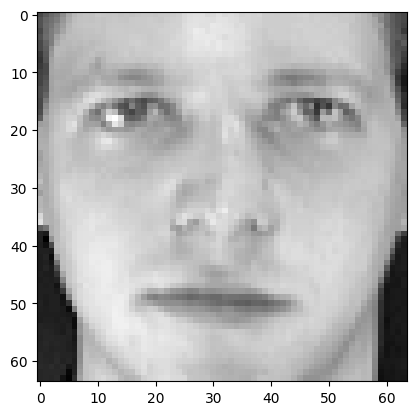

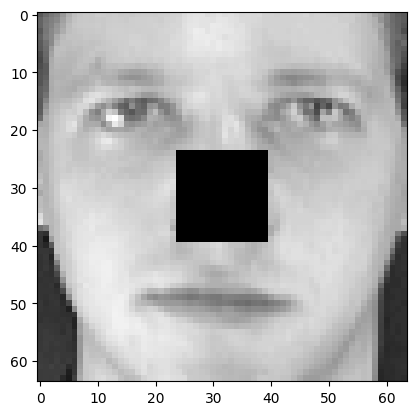

In [ ]:
# Display one original and masked face

plt.imshow(X_test[0].reshape(64,64), cmap='gray')
plt.show()
plt.imshow(X_test_masked[0], cmap='gray')
plt.show()